In [33]:
# import the library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [4]:
# load the datasets.
df = pd.read_csv("placement_dataset.csv")
df.head()

,CGPA,ScoreBias,Placed
0,3.8,85,1
1,3.2,72,0
2,3.9,88,1
3,2.5,65,0
4,3.5,79,1


In [5]:
# stastical summary
df.describe()

,CGPA,ScoreBias,Placed
count,50.000000,50.000000,50.000000
mean,3.218000,75.880000,0.520000
std,0.521258,8.800835,0.504672
min,2.200000,60.000000,0.000000
25%,2.800000,69.250000,0.000000
50%,3.250000,75.500000,1.000000
75%,3.700000,83.000000,1.000000
max,4.000000,92.000000,1.000000


In [6]:
# Null values
df.isnull().sum()

CGPA         0
ScoreBias    0
Placed       0
dtype: int64

In [7]:
# Scaling the data by using standard scaler
from sklearn.preprocessing import StandardScaler
slr = StandardScaler()
df['ScoreBias'] = slr.fit_transform(df[['ScoreBias']])

In [8]:
df.head()

,CGPA,ScoreBias,Placed
0,3.8,1.046786,1
1,3.2,-0.445343,0
2,3.9,1.391124,1
3,2.5,-1.248797,0
4,3.5,0.358111,1


In [9]:
df['Placed'].value_counts()

Placed
1    26
0    24
Name: count, dtype: int64

<Axes: xlabel='CGPA', ylabel='ScoreBias'>

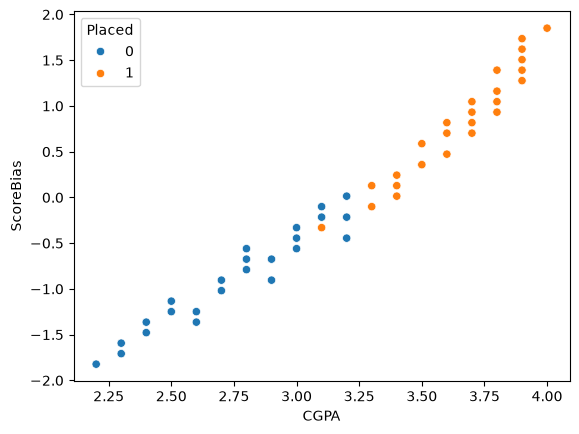

In [10]:
sns.scatterplot(x = 'CGPA' , y = 'ScoreBias',hue='Placed',data=df)

In [11]:
# Differentating the feature and target columns.
x = df.drop('Placed',axis=1)
y = df['Placed']

In [12]:
# train test split of our datsets.
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)


In [13]:
# train the model using logistic regression model.
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(x_train,y_train)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [14]:
y_pred = model.predict(x_test)


In [15]:
# let's comaprision the test data with predtiction data.
pred = pd.DataFrame({'Actual_data':y_test,'Predection_data':y_pred})
print(pred)

    Actual_data  Predection_data
13            0                0
39            0                0
30            1                1
45            0                0
17            0                0
48            1                1
26            1                1
25            0                0
32            1                1
19            0                0


In [24]:
# Evolution and performance the model 
from sklearn.metrics import confusion_matrix,precision_score,recall_score,f1_score,accuracy_score


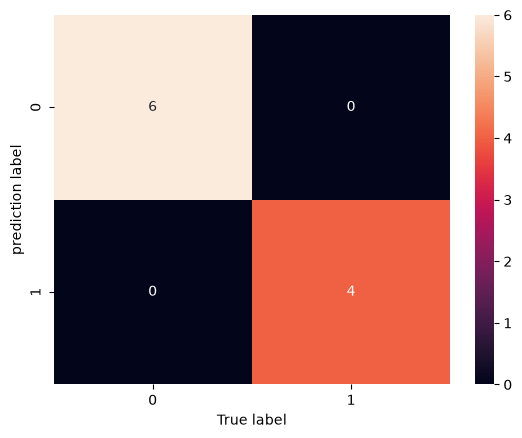

In [19]:
sns.heatmap(confusion_matrix(y_test,y_pred),annot=True)
plt.xlabel("True label")
plt.ylabel("prediction label")
plt.show()

In [21]:
precision_score(y_test,y_pred) * 100

100.0

In [23]:
recall_score(y_test,y_pred) * 100

100.0

In [26]:
accuracy_score(y_test,y_pred) * 100

100.0

c:\Data_Science\env\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


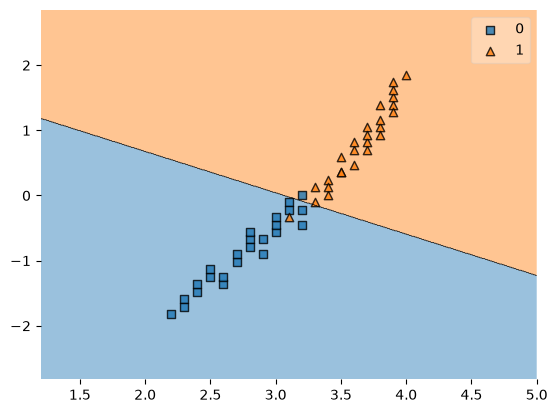

In [29]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(x.to_numpy(),y.to_numpy(),clf=model)
plt.show()


In [32]:
print(model.score(x_test,y_test) * 100)

100.0


In [34]:
# save the model.
joblib.dump(model,'model.pkl')

['model.pkl']